In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = sns.load_dataset("iris")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print("First 5 rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nSpecies Value Counts:")
display(df["species"].value_counts())

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species Value Counts:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [4]:
df["sepal_length"] = df["sepal_length"].fillna(df["sepal_length"].mean())
df["sepal_width"] = df["sepal_width"].fillna(df["sepal_width"].mean())
df["petal_length"] = df["petal_length"].fillna(df["petal_length"].mean())
df["petal_width"] = df["petal_width"].fillna(df["petal_width"].mean())
df["species"] = df["species"].fillna("Unknown")

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [5]:
selected_data = df[
    ["sepal_length", "sepal_width", "petal_length", "petal_width"]
]

display(selected_data.head())

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [6]:
filtered_data = df[df["petal_length"] > 5]

print("Flowers with petal length greater than 5:")
display(filtered_data.head())

print("Number of filtered rows:", len(filtered_data))

Flowers with petal length greater than 5:


,sepal_length,sepal_width,petal_length,petal_width,species
83,6.0,2.7,5.1,1.6,versicolor
100,6.3,3.3,6.0,2.5,virginica
101,5.8,2.7,5.1,1.9,virginica
102,7.1,3.0,5.9,2.1,virginica
103,6.3,2.9,5.6,1.8,virginica


Number of filtered rows: 42


In [7]:
grouped_data = df.groupby("species").agg(
    average_sepal_length=("sepal_length", "mean"),
    average_sepal_width=("sepal_width", "mean"),
    average_petal_length=("petal_length", "mean"),
    average_petal_width=("petal_width", "mean")
)

display(grouped_data)

,average_sepal_length,average_sepal_width,average_petal_length,average_petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [8]:
sns.set_theme(style="whitegrid")

print("Seaborn theme applied successfully!")

Seaborn theme applied successfully!


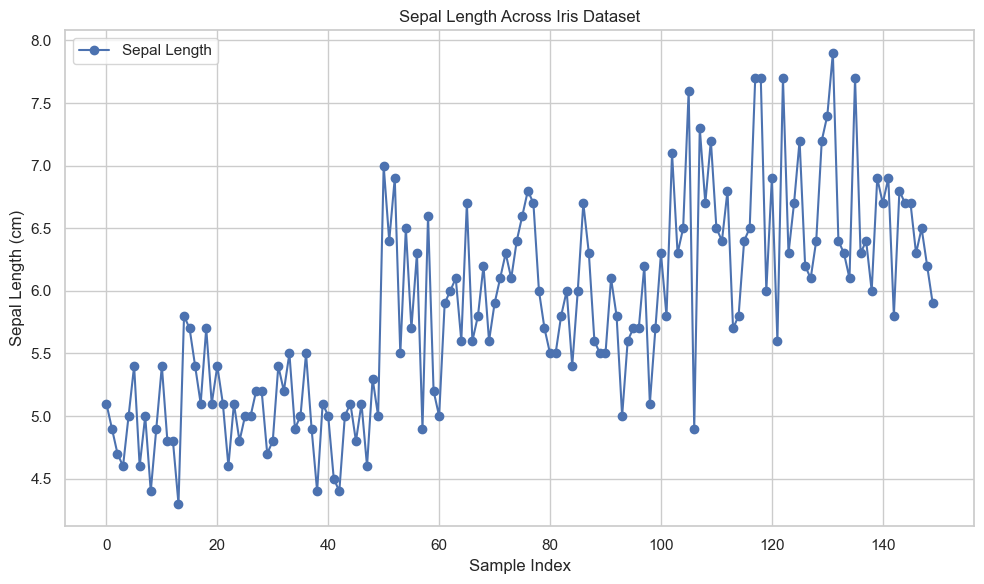

In [9]:
plt.figure(figsize=(10, 6))

plt.plot(
    df.index,
    df["sepal_length"],
    marker="o",
    label="Sepal Length"
)

plt.title("Sepal Length Across Iris Dataset")
plt.xlabel("Sample Index")
plt.ylabel("Sepal Length (cm)")
plt.legend()

plt.tight_layout()
plt.savefig("line_chart.png", dpi=300, bbox_inches="tight")
plt.show()

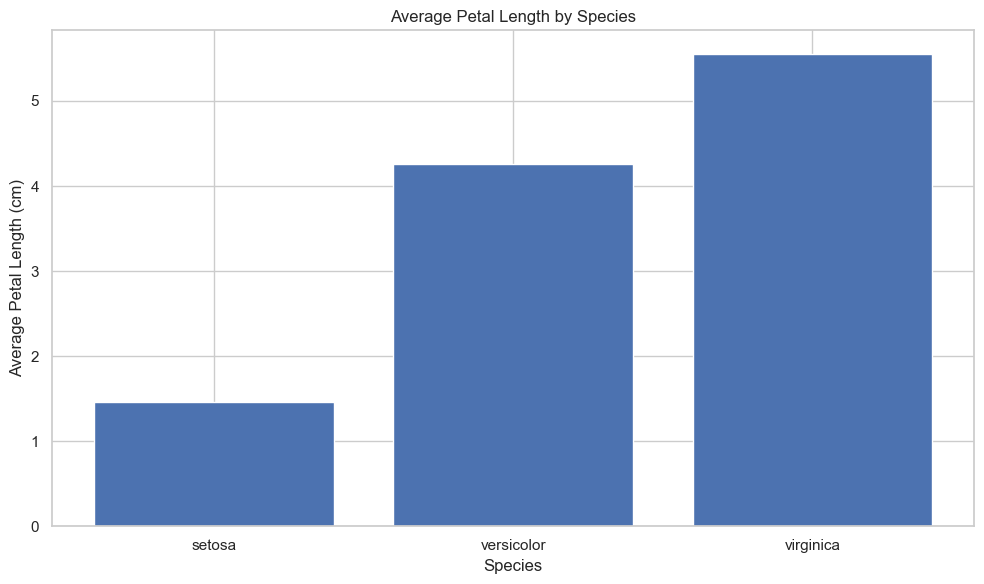

In [10]:
species_average = df.groupby("species")["petal_length"].mean()

plt.figure(figsize=(10, 6))

plt.bar(
    species_average.index,
    species_average.values
)

plt.title("Average Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Average Petal Length (cm)")

plt.tight_layout()
plt.savefig("bar_chart.png", dpi=300, bbox_inches="tight")
plt.show()

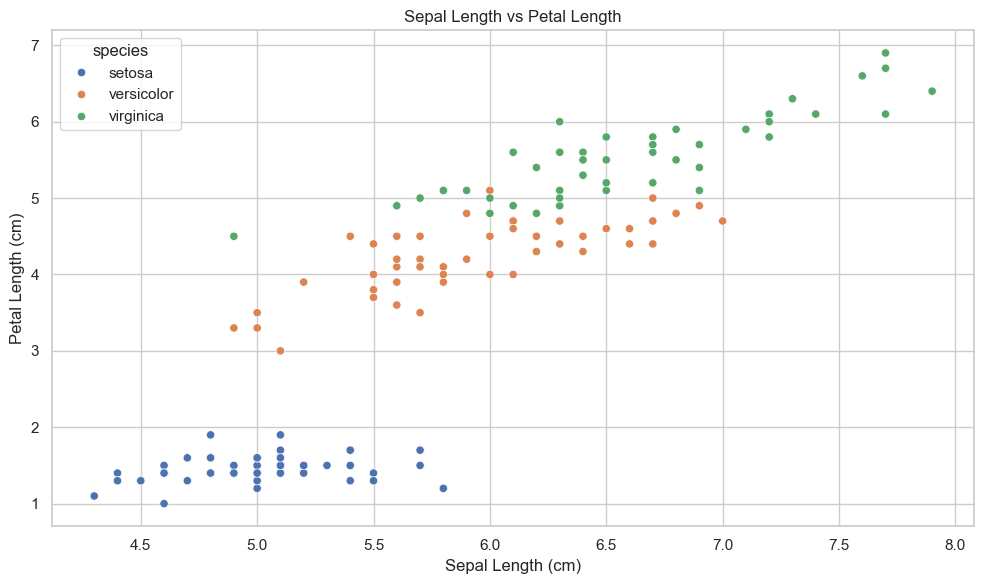

In [11]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="sepal_length",
    y="petal_length",
    hue="species"
)

plt.title("Sepal Length vs Petal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")

plt.tight_layout()
plt.savefig("scatter_chart.png", dpi=300, bbox_inches="tight")
plt.show()

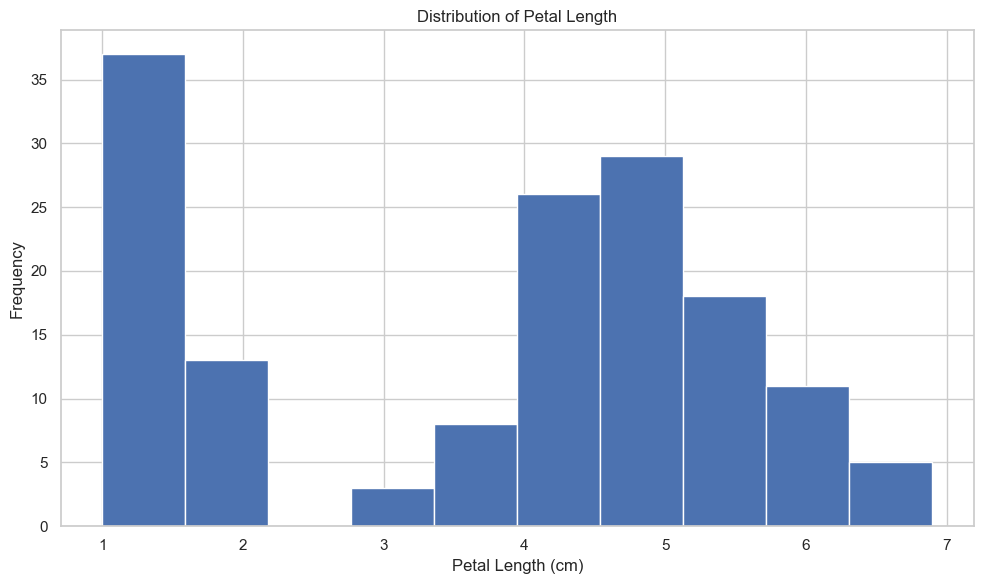

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["petal_length"],
    bins=10
)

plt.title("Distribution of Petal Length")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("histogram.png", dpi=300, bbox_inches="tight")
plt.show()

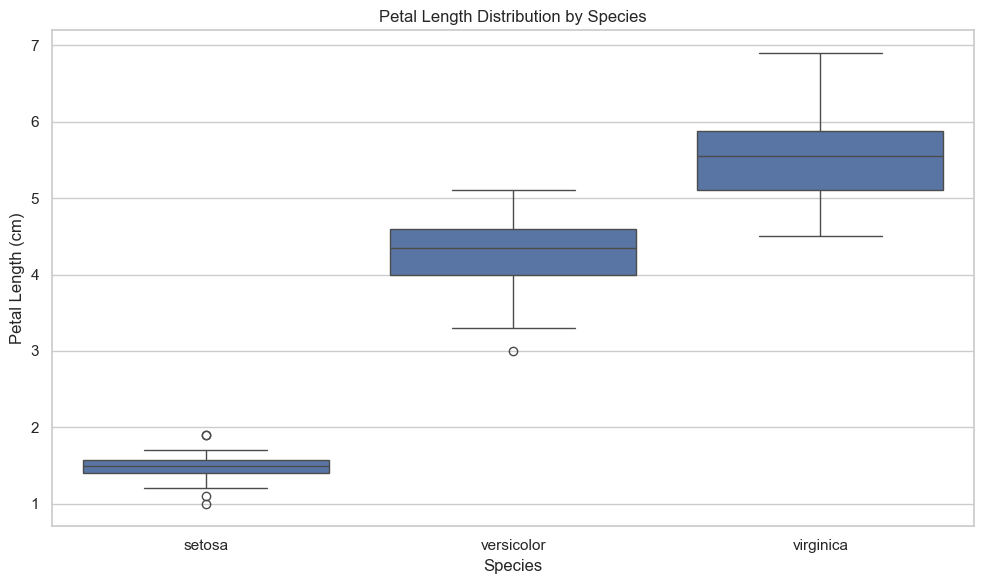

In [13]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="species",
    y="petal_length"
)

plt.title("Petal Length Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Petal Length (cm)")

plt.tight_layout()
plt.savefig("box_plot.png", dpi=300, bbox_inches="tight")
plt.show()

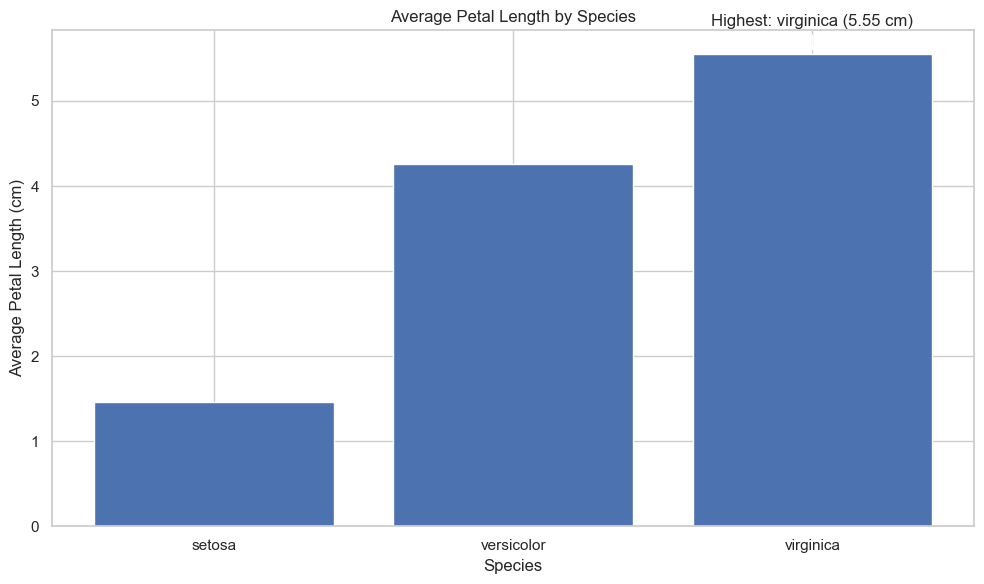

In [14]:
species_average = df.groupby("species")["petal_length"].mean()

highest_species = species_average.idxmax()
highest_value = species_average.max()

plt.figure(figsize=(10, 6))

plt.bar(
    species_average.index,
    species_average.values
)

plt.title("Average Petal Length by Species")
plt.xlabel("Species")
plt.ylabel("Average Petal Length (cm)")

plt.annotate(
    f"Highest: {highest_species} ({highest_value:.2f} cm)",
    xy=(highest_species, highest_value),
    xytext=(0, 20),
    textcoords="offset points",
    ha="center",
    arrowprops=dict(arrowstyle="->")
)

plt.tight_layout()
plt.savefig("annotated_chart.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
df.to_csv("cleaned_iris_dataset.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [16]:
print("FINAL DATASET INFORMATION")
print("--------------------------")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumns:")
print(list(df.columns))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Counts:")
print(df["species"].value_counts())

print("\nEDA completed successfully!")

FINAL DATASET INFORMATION
--------------------------
Rows: 150
Columns: 5

Columns:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species Counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

EDA completed successfully!
